
---
date: "2026-10-24"
date-modified: last-modified
format:
  html:
    toc: true
---


# The Intermediate Value Theorem

**Prerequisites:** [Continuous Functions](function-continuity.ipynb) · [Nested Interval Property](nested-interval-property.ipynb)

::: {#lem-bolzano}
## A Continuous Function Changing Sign Has a Zero

Let $g : [\alpha, \beta] \to \mathbb{R}$ be continuous with $g(\alpha) < 0 < g(\beta)$. Then $g(r) = 0$ for some $r \in (\alpha, \beta)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @lem-bolzano
**Bisection.** Let $I_0 = [\alpha_0, \beta_0] = [\alpha, \beta]$. Given $I_n = [\alpha_n, \beta_n]$ with $g(\alpha_n) < 0 < g(\beta_n)$, let $m$ be its midpoint. If $g(m) = 0$ we are done. Otherwise let $I_{n+1}$ be the half $[\alpha_n, m]$ or $[m, \beta_n]$ on which $g$ is still negative at the left end and positive at the right end. The intervals are nested with lengths $(\beta - \alpha)2^{-n} \to 0$, so by the [nested interval property](nested-interval-property.ipynb) they contain a common point $r$, and $\alpha_n \to r$, $\beta_n \to r$.

If $g(r) > 0$, continuity gives $\delta > 0$ with $g > 0$ on $(r - \delta, r + \delta) \cap [\alpha, \beta]$ (take $\varepsilon = g(r)$). For $n$ large, $I_n \subseteq (r - \delta, r + \delta)$, but $g(\alpha_n) < 0$: contradiction. If $g(r) < 0$, the same argument with $\beta_n$. So $g(r) = 0$, and $r \ne \alpha, \beta$. $\blacksquare$
:::

::: {#thm-ivt}
## Intermediate Value Theorem

Let $f : [a, b] \to \mathbb{R}$ be continuous and let $C$ lie between $f(a)$ and $f(b)$. Then $f(c) = C$ for some $c \in [a, b]$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-ivt
If $C = f(a)$ or $C = f(b)$ there is nothing to prove. If $f(a) < C < f(b)$, apply @lem-bolzano to $g = f - C$. If $f(a) > C > f(b)$, apply it to $g = C - f$. $\blacksquare$
:::

::: {#cor-image-interval}
## Continuous Images of Intervals Are Intervals

If $I$ is an interval and $f : I \to \mathbb{R}$ is continuous, then $f(I)$ is an interval: whenever $y_1 < y < y_2$ with $y_1, y_2 \in f(I)$, also $y \in f(I)$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-image-interval
Let $y_1 = f(x_1)$, $y_2 = f(x_2)$. Apply @thm-ivt to $f$ on the closed interval with endpoints $x_1, x_2$, which lies in $I$. $\blacksquare$
:::

::: {#exm-ivt}
## Applications

1. *Counting roots.* $f(x) = \sin x - x^2 + x + 3$ has at least two zeros in $[-\pi, \pi]$: $f(0) = 3 > 0$, while $f(\pm\pi) = -\pi^2 \pm \pi + 3 < 0$ (as $\pi^2 > \pi + 3$).
2. *Fixed points.* Every continuous $f : [a, b] \to [a, b]$ has a fixed point $f(c) = c$: the function $\varphi(x) = x - f(x)$ satisfies $\varphi(a) \le 0 \le \varphi(b)$.
3. *Odd degree.* Every real polynomial $P(x) = a_nx^n + \dots + a_0$ of odd degree $n$ has a real zero. Write $P(x) = a_n x^n\big(1 + \sum_{k<n} \frac{a_k}{a_n}x^{k-n}\big)$. For $|x| \ge 1 + \sum_{k<n}\big|\frac{a_k}{a_n}\big|$ the sum in the bracket has modulus $< 1$, so $P(x)$ has the sign of $a_nx^n$, which is opposite at $x$ and $-x$.
4. *Roots.* For $a > 0$, $x^n - a$ is negative at $0$ and positive at $1 + a$, which gives another proof of the [existence of $\sqrt[n]{a}$](existence-of-nth-roots-in-R.ipynb#thm-nth-root).
:::

The figure shows the bisection of the proof for $g(x) = x^3 - 2x - 1$ on $[1, 2]$, where $g(1) = -2 < 0 < g(2) = 3$; the zero is $\frac{1 + \sqrt5}{2}$.

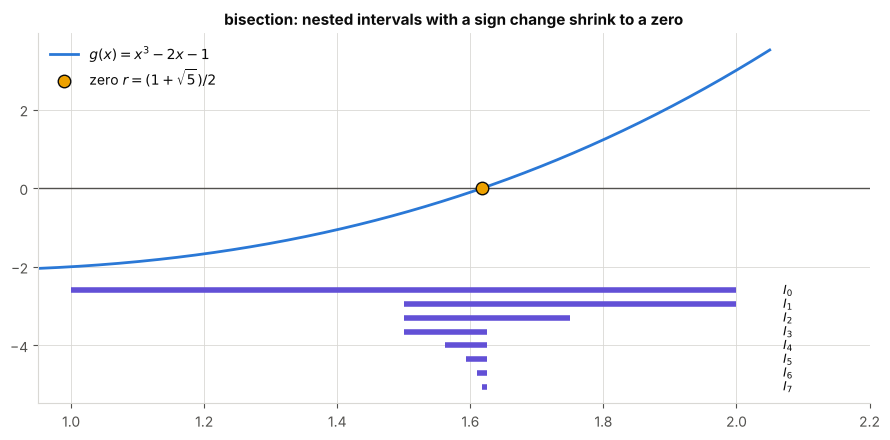

last interval: (1.6171875, 1.625) | r = 1.618033988749895


In [1]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

g = lambda x: x**3 - 2*x - 1
lo, hi = 1.0, 2.0
intervals = [(lo, hi)]
for _ in range(7):
    m = (lo + hi) / 2
    lo, hi = (lo, m) if g(m) > 0 else (m, hi)
    intervals.append((lo, hi))

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.linspace(0.95, 2.05, 400)
ax.plot(x, g(x), color=BLUE, lw=2, label=r"$g(x) = x^3 - 2x - 1$")
ax.axhline(0, color=MUTED, lw=1)
for k, (a, b) in enumerate(intervals):
    y = -2.6 - 0.35 * k
    ax.plot([a, b], [y, y], color=VIOLET, lw=4, solid_capstyle="butt")
    ax.text(2.07, y, f"$I_{k}$", va="center", fontsize=9)
root = (1 + 5 ** 0.5) / 2
ax.plot(root, 0, "o", color=YELLOW, ms=9, mec=INK, label=r"zero $r = (1+\sqrt{5})/2$")
ax.set_xlim(0.95, 2.2); ax.legend(loc="upper left")
ax.set_title("bisection: nested intervals with a sign change shrink to a zero")
plt.tight_layout(); plt.show()
print("last interval:", intervals[-1], "| r =", root)